<!-- @format -->

# Sparse Autoencoder


In [14]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "data_loader.py").is_file()
    and (PROJECT_ROOT / "models" / "mlp_classifier.py").is_file()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: D:\Main\sem5\deep-learning\ASG_2


In [23]:
import json
import time

import matplotlib.pyplot as plt
import torch
from torch import nn, optim

from data_loader import get_dataloaders
from models.autoencoder import build_vanilla_autoencoder
from utils.metrics import psnr, ssim
from utils.paths import (
    CHECKPOINT_DIR,
    DATA_DIR,
    FIGURES_DIR,
    METRICS_DIR,
    ensure_results_dirs,
    get_device,
)
from utils.reproducibility import set_seed
from models.sparse_autoencoder import build_sparse_autoencoder

In [16]:
SEED = 42
BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001
LATENT_DIM = 64
SPARSITY_WEIGHT = 0.001


DEVICE = get_device()
ensure_results_dirs()

print(f"Device: {DEVICE}")


Device: xpu


In [17]:
print(f"Device: {DEVICE}")
print(f"Latent dimension: {LATENT_DIM}")
print(f"Sparsity weight: {SPARSITY_WEIGHT}")


Device: xpu
Latent dimension: 64
Sparsity weight: 0.001


In [18]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=BATCH_SIZE)

print(f"Training batches:   {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Testing batches:    {len(test_loader)}")

# Inspect one batch
images, labels = next(iter(train_loader))

print("\nBatch inspection:")
print(f"Images shape: {images.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Pixel range: [{images.min():.4f}, {images.max():.4f}]")


Training batches:   438
Validation batches: 55
Testing batches:    55

Batch inspection:
Images shape: torch.Size([128, 1, 28, 28])
Labels shape: torch.Size([128])
Pixel range: [0.0000, 1.0000]


In [24]:
encoder, decoder = build_sparse_autoencoder(latent_dim=LATENT_DIM)

encoder = encoder.to(DEVICE)
decoder = decoder.to(DEVICE)

print("Encoder:")
print(encoder)

print("\nDecoder:")
print(decoder)

# Test forward pass
sample_images, _ = next(iter(train_loader))
sample_images = sample_images.to(DEVICE)

with torch.no_grad():
    latent = encoder(sample_images)
    reconstructed = decoder(latent)

print("\nTensor inspection:")
print(f"Input:           {sample_images.shape}")
print(f"Latent:          {latent.shape}")
print(f"Reconstruction:  {reconstructed.shape}")


Encoder:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=64, bias=True)
  (4): ReLU()
)

Decoder:
Sequential(
  (0): Linear(in_features=64, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=784, bias=True)
  (3): Sigmoid()
  (4): Unflatten(dim=1, unflattened_size=(1, 28, 28))
)

Tensor inspection:
Input:           torch.Size([128, 1, 28, 28])
Latent:          torch.Size([128, 64])
Reconstruction:  torch.Size([128, 1, 28, 28])


In [25]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    list(encoder.parameters()) + list(decoder.parameters()), lr=LEARNING_RATE
)


def sparse_autoencoder_loss(reconstructed, original, latent, sparsity_weight):
    reconstruction_loss = criterion(reconstructed, original)

    sparsity_loss = torch.mean(torch.abs(latent))

    total_loss = reconstruction_loss + sparsity_weight * sparsity_loss

    return total_loss, reconstruction_loss, sparsity_loss


print("Loss function: MSE + L1 Sparsity Penalty")
print(f"Sparsity weight: {SPARSITY_WEIGHT}")
print(f"Optimizer: Adam")
print(f"Learning rate: {LEARNING_RATE}")


Loss function: MSE + L1 Sparsity Penalty
Sparsity weight: 0.001
Optimizer: Adam
Learning rate: 0.001


In [26]:
history = {
    "train_total_loss": [],
    "train_reconstruction_loss": [],
    "train_sparsity_loss": [],
    "val_reconstruction_loss": [],
}

best_val_loss = float("inf")
best_checkpoint_path = CHECKPOINT_DIR / "sparse_ae_best.pth"

for epoch in range(EPOCHS):
    start_time = time.time()

    # Training
    encoder.train()
    decoder.train()

    train_total = 0.0
    train_reconstruction = 0.0
    train_sparsity = 0.0

    for images, _ in train_loader:
        images = images.to(DEVICE)

        optimizer.zero_grad()

        latent = encoder(images)
        reconstructed = decoder(latent)

        total_loss, reconstruction_loss, sparsity_loss = sparse_autoencoder_loss(
            reconstructed,
            images,
            latent,
            SPARSITY_WEIGHT,
        )

        total_loss.backward()
        optimizer.step()

        train_total += total_loss.item()
        train_reconstruction += reconstruction_loss.item()
        train_sparsity += sparsity_loss.item()

    num_train_batches = len(train_loader)

    train_total /= num_train_batches
    train_reconstruction /= num_train_batches
    train_sparsity /= num_train_batches

    # Validation
    encoder.eval()
    decoder.eval()

    val_reconstruction = 0.0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(DEVICE)

            latent = encoder(images)
            reconstructed = decoder(latent)

            loss = criterion(reconstructed, images)
            val_reconstruction += loss.item()

    val_reconstruction /= len(val_loader)

    # Save history
    history["train_total_loss"].append(train_total)
    history["train_reconstruction_loss"].append(train_reconstruction)
    history["train_sparsity_loss"].append(train_sparsity)
    history["val_reconstruction_loss"].append(val_reconstruction)

    # Save best checkpoint
    if val_reconstruction < best_val_loss:
        best_val_loss = val_reconstruction

        torch.save(
            {
                "epoch": epoch + 1,
                "encoder_state_dict": encoder.state_dict(),
                "decoder_state_dict": decoder.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_reconstruction_loss": best_val_loss,
                "latent_dim": LATENT_DIM,
                "sparsity_weight": SPARSITY_WEIGHT,
                "history": history,
            },
            best_checkpoint_path,
        )

    epoch_time = time.time() - start_time

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"| Train Total: {train_total:.6f} "
        f"| Train Recon: {train_reconstruction:.6f} "
        f"| Train Sparse: {train_sparsity:.6f} "
        f"| Val Recon: {val_reconstruction:.6f} "
        f"| Time: {epoch_time:.2f}s"
    )

print("\nTraining completed.")
print(f"Best validation reconstruction loss: {best_val_loss:.6f}")
print(f"Checkpoint saved at: {best_checkpoint_path}")


Epoch [01/30] | Train Total: 0.035238 | Train Recon: 0.034258 | Train Sparse: 0.980457 | Val Recon: 0.019685 | Time: 19.93s
Epoch [02/30] | Train Total: 0.018252 | Train Recon: 0.017479 | Train Sparse: 0.773131 | Val Recon: 0.015999 | Time: 19.73s
Epoch [03/30] | Train Total: 0.015470 | Train Recon: 0.014749 | Train Sparse: 0.720881 | Val Recon: 0.014048 | Time: 11.71s
Epoch [04/30] | Train Total: 0.013925 | Train Recon: 0.013227 | Train Sparse: 0.697879 | Val Recon: 0.012831 | Time: 12.24s
Epoch [05/30] | Train Total: 0.012855 | Train Recon: 0.012171 | Train Sparse: 0.683862 | Val Recon: 0.011932 | Time: 11.74s
Epoch [06/30] | Train Total: 0.012039 | Train Recon: 0.011366 | Train Sparse: 0.673192 | Val Recon: 0.011340 | Time: 14.08s
Epoch [07/30] | Train Total: 0.011472 | Train Recon: 0.010814 | Train Sparse: 0.657925 | Val Recon: 0.010850 | Time: 13.75s
Epoch [08/30] | Train Total: 0.011022 | Train Recon: 0.010378 | Train Sparse: 0.644228 | Val Recon: 0.010432 | Time: 13.18s
Epoch [0

In [27]:
checkpoint = torch.load(
    best_checkpoint_path,
    map_location=DEVICE,
    weights_only=False,
)

encoder.load_state_dict(checkpoint["encoder_state_dict"])
decoder.load_state_dict(checkpoint["decoder_state_dict"])

encoder.eval()
decoder.eval()

print(f"Best epoch: {checkpoint['epoch']}")
print(f"Best validation MSE: {checkpoint['val_reconstruction_loss']:.6f}")
print(f"Latent dimension: {checkpoint['latent_dim']}")
print(f"Sparsity weight: {checkpoint['sparsity_weight']}")


Best epoch: 30
Best validation MSE: 0.007994
Latent dimension: 64
Sparsity weight: 0.001


In [28]:
test_mse = 0.0
test_psnr = 0.0
test_ssim = 0.0

num_samples = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)

        latent = encoder(images)
        reconstructed = decoder(latent)

        batch_size = images.size(0)

        test_mse += torch.nn.functional.mse_loss(
            reconstructed,
            images,
            reduction="sum",
        ).item()

        test_psnr += psnr(reconstructed, images).item() * batch_size
        test_ssim += ssim(reconstructed, images).item() * batch_size

        num_samples += batch_size

test_mse /= num_samples
test_psnr /= num_samples
test_ssim /= num_samples

print("Sparse Autoencoder Test Results")
print(f"Test MSE:  {test_mse:.6f}")
print(f"Test PSNR: {test_psnr:.4f} dB")
print(f"Test SSIM: {test_ssim:.4f}")


Sparse Autoencoder Test Results
Test MSE:  6.228437
Test PSNR: 21.0091 dB
Test SSIM: 0.7519


In [29]:
latent_activations = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)
        latent = encoder(images)
        latent_activations.append(latent.cpu())

latent_activations = torch.cat(latent_activations, dim=0)

# Calculate sparsity statistics
zero_threshold = 1e-6

zero_activation_ratio = (
    (latent_activations.abs() < zero_threshold).float().mean().item()
)

mean_activation = latent_activations.abs().mean().item()

mean_active_neurons = (
    (latent_activations.abs() >= zero_threshold).float().sum(dim=1).mean().item()
)

print("Latent Sparsity Analysis")
print(f"Latent shape: {latent_activations.shape}")
print(f"Zero activation ratio: {zero_activation_ratio:.4%}")
print(f"Mean absolute activation: {mean_activation:.6f}")
print(f"Mean active neurons per sample: {mean_active_neurons:.2f}/{LATENT_DIM}")


Latent Sparsity Analysis
Latent shape: torch.Size([7000, 64])
Zero activation ratio: 27.9536%
Mean absolute activation: 0.485871
Mean active neurons per sample: 46.11/64


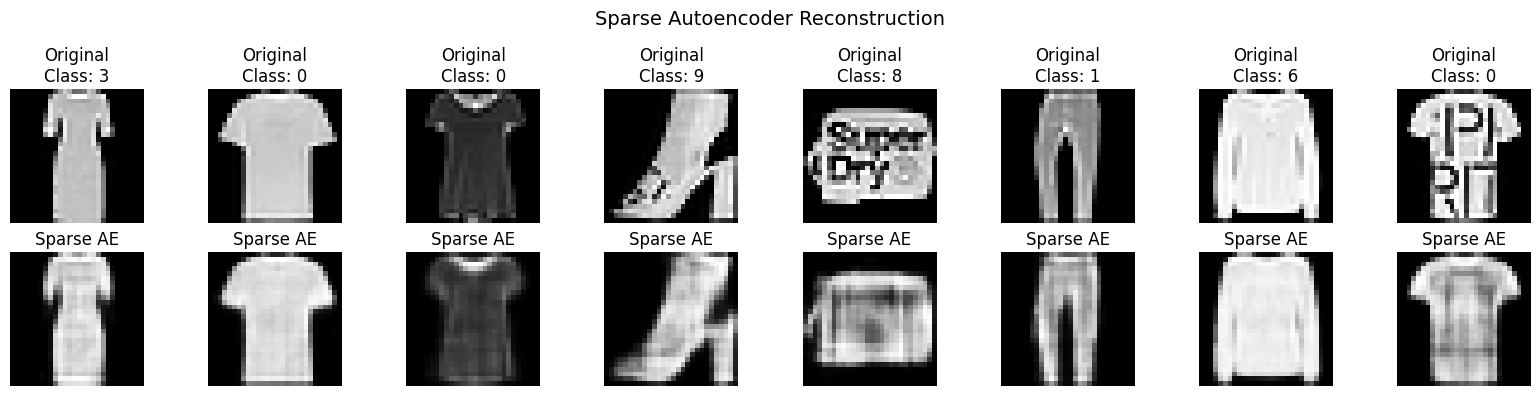

In [30]:
encoder.eval()
decoder.eval()

images, labels = next(iter(test_loader))
images = images[:8].to(DEVICE)
labels = labels[:8]

with torch.no_grad():
    latent = encoder(images)
    reconstructed = decoder(latent)

images = images.cpu()
reconstructed = reconstructed.cpu()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    # Original
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].set_title(f"Original\nClass: {labels[i].item()}")
    axes[0, i].axis("off")

    # Reconstruction
    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1, i].set_title("Sparse AE")
    axes[1, i].axis("off")

plt.suptitle("Sparse Autoencoder Reconstruction", fontsize=14)
plt.tight_layout()
plt.show()


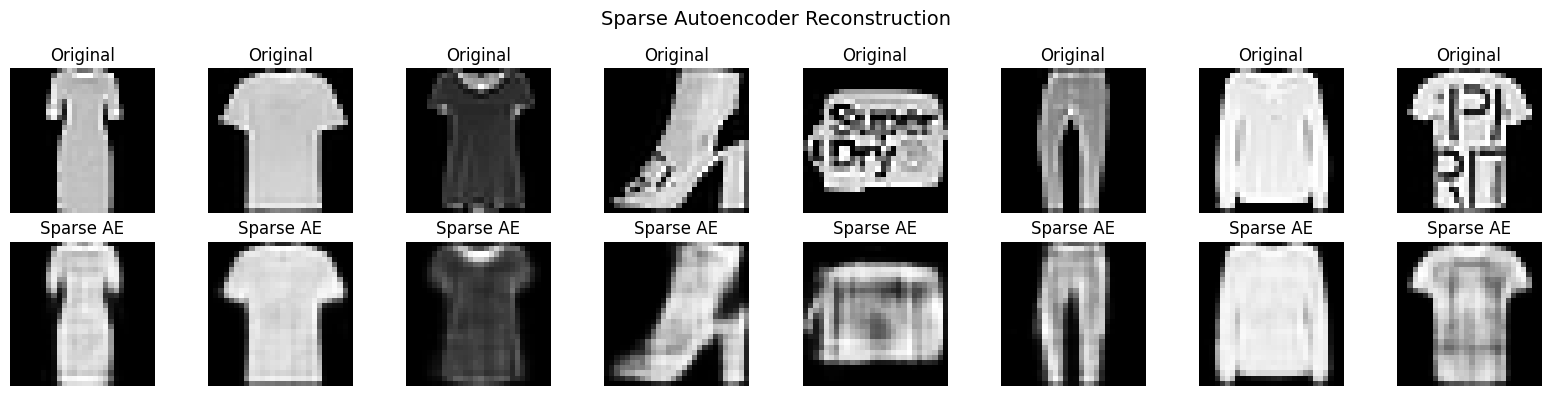

Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\sparse_ae_reconstruction.png


In [31]:
reconstruction_path = FIGURES_DIR / "sparse_ae_reconstruction.png"

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1, i].set_title("Sparse AE")
    axes[1, i].axis("off")

plt.suptitle("Sparse Autoencoder Reconstruction", fontsize=14)
plt.tight_layout()
plt.savefig(reconstruction_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved: {reconstruction_path}")


In [32]:
sparse_ae_metrics = {
    "model": "Sparse Autoencoder",
    "configuration": {
        "latent_dim": LATENT_DIM,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "sparsity_weight": SPARSITY_WEIGHT,
        "seed": SEED,
    },
    "test_metrics": {
        "mse": test_mse,
        "psnr": test_psnr,
        "ssim": test_ssim,
    },
    "latent_sparsity": {
        "zero_activation_ratio": zero_activation_ratio,
        "mean_absolute_activation": mean_activation,
        "mean_active_neurons": mean_active_neurons,
        "zero_threshold": zero_threshold,
    },
    "training": {
        "best_epoch": checkpoint["epoch"],
        "best_validation_mse": best_val_loss,
        "best_checkpoint": str(best_checkpoint_path.relative_to(PROJECT_ROOT)),
    },
}

metrics_path = METRICS_DIR / "sparse_ae.json"

with open(metrics_path, "w") as file:
    json.dump(sparse_ae_metrics, file, indent=4)

print(f"Metrics saved: {metrics_path}")


Metrics saved: D:\Main\sem5\deep-learning\ASG_2\results\metrics\sparse_ae.json


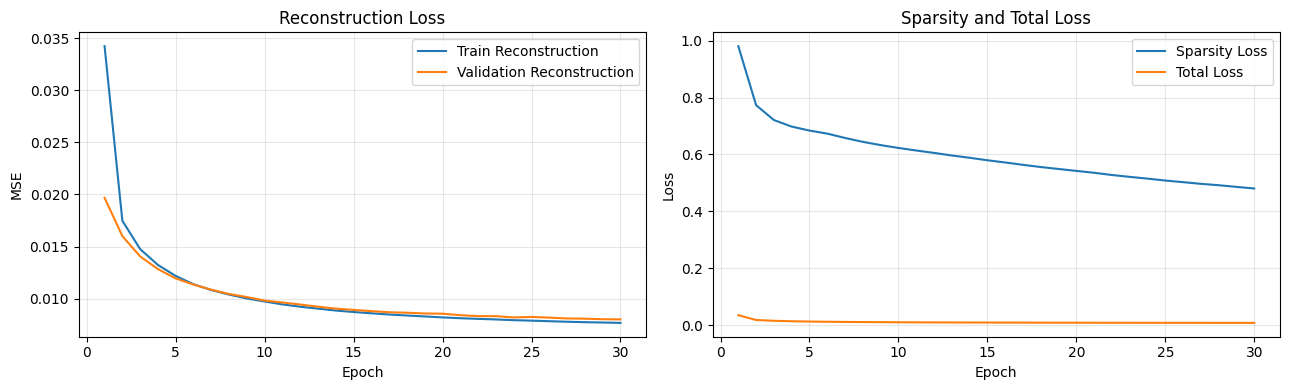

Training curves saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\sparse_ae_training_curves.png


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

epochs_range = range(1, len(history["train_total_loss"]) + 1)

# Reconstruction loss
axes[0].plot(
    epochs_range,
    history["train_reconstruction_loss"],
    label="Train Reconstruction",
)
axes[0].plot(
    epochs_range,
    history["val_reconstruction_loss"],
    label="Validation Reconstruction",
)
axes[0].set_title("Reconstruction Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Sparsity and total loss
axes[1].plot(
    epochs_range,
    history["train_sparsity_loss"],
    label="Sparsity Loss",
)
axes[1].plot(
    epochs_range,
    history["train_total_loss"],
    label="Total Loss",
)
axes[1].set_title("Sparsity and Total Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

training_curve_path = FIGURES_DIR / "sparse_ae_training_curves.png"

plt.savefig(training_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Training curves saved: {training_curve_path}")
